In [29]:
import numpy as np
import matplotlib.pyplot as plt


data = np.array([80354, 80360.2,80366.6,80375,80376,80433.5])
data_uncertainty = np.array([32, 9.9, 15.9, 23, 33, 6.4])

First calculate the basic mean

In [30]:
# calculate the mean and combined error

mean = np.mean(data)
combined_error = np.sqrt(np.sum(data_uncertainty**2)) / len(data)
print(f"Mean: {mean}, Combined Error: {combined_error}")

Mean: 80377.55, Combined Error: 9.179960058010419


Now lets use the BLUE method 

In [31]:
# Use the BLUE method to calculate the best estimate and its uncertainty

weights = 1 / data_uncertainty**2
best_estimate = np.sum(weights * data) / np.sum(weights)
best_estimate_uncertainty = np.sqrt(1 / np.sum(weights))
print(f"Best Estimate: {best_estimate}, Best Estimate Uncertainty: {best_estimate_uncertainty}")    

Best Estimate: 80403.9061396997, Best Estimate Uncertainty: 4.858845695581695


Show that a linear fit with gradient zero is equal 

In [32]:
# Use a chi-squared linear fit with gradient fixed at 1

x = np.array([1, 2, 3, 4, 5, 6])
y = data

def linear_fit(x, y, y_err):
    m = 0
    w = 1.0 / y_err**2
    c = np.sum(w * (y - m * x)) / np.sum(w)
    c_err = np.sqrt(1.0 / np.sum(w))
    chi2 = np.sum(((y - (m * x + c)) / y_err) ** 2)
    return c, c_err, chi2

c, c_err, chi2 = linear_fit(x, y, data_uncertainty)
print(f"Best-fit intercept with m=0: {c} ± {c_err}")
print(f"Chi-squared: {chi2}")

Best-fit intercept with m=0: 80403.9061396997 ± 4.858845695581695
Chi-squared: 51.103861362961396


Lets look at the point and the fit 

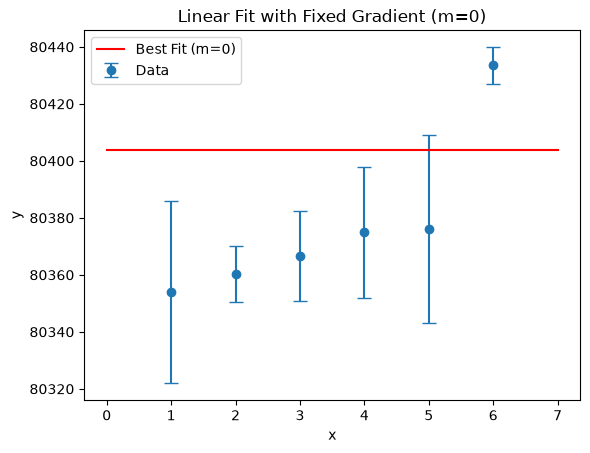

In [33]:
# plot the data and the fit 

plt.errorbar(x, y, yerr=data_uncertainty, fmt='o', label='Data', capsize=5)
x_fit = np.linspace(0, 7, 100)
y_fit = np.full_like(x_fit, c)
plt.plot(x_fit, y_fit, label='Best Fit (m=0)', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Fit with Fixed Gradient (m=0)')
plt.legend()

We notice that our outlier has a very low error and thus massively skews our fit :(

In [34]:
# perform fit again after removing the outlier

x = np.array([1, 2, 3, 4, 5])
y = data[:-1]
y_err = data_uncertainty[:-1]

def linear_fit(x, y, y_err):
    m = 0
    w = 1.0 / y_err**2
    c = np.sum(w * (y - m * x)) / np.sum(w)
    c_err = np.sqrt(1.0 / np.sum(w))
    chi2 = np.sum(((y - (m * x + c)) / y_err) ** 2)
    return c, c_err, chi2

c, c_err, chi2 = linear_fit(x, y, y_err)
print(f"Best-fit intercept with m=0: {c} ± {c_err}")
print(f"Chi-squared: {chi2}")

weights = 1 / y_err**2
combination = np.sum(weights * y) / np.sum(weights)
unc_combination = np.sqrt(1 / np.sum(weights))
outlier = data[-1]
unc_outlier = data_uncertainty[-1]
sigma = (outlier - combination) / np.sqrt(unc_outlier**2 + unc_combination**2)
print(f"Combination: {combination} ± {unc_combination}")
print(f"Outlier: {outlier} ± {unc_outlier}")
print(f"Difference in sigma: {sigma}")

Best-fit intercept with m=0: 80363.64112675173 ± 7.465228163888806
Chi-squared: 0.6303814888188581
Combination: 80363.64112675173 ± 7.465228163888806
Outlier: 80433.5 ± 6.4
Difference in sigma: 7.104469007191844


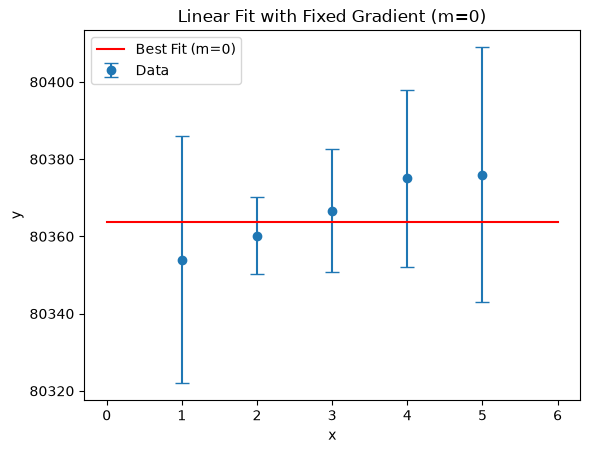

In [36]:
# plot the consistent data and the fit

plt.errorbar(x, y, yerr=y_err, fmt='o', label='Data', capsize=5)
x_fit = np.linspace(0, 6, 100)
y_fit = np.full_like(x_fit, c)
plt.plot(x_fit, y_fit, label='Best Fit (m=0)', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Fit with Fixed Gradient (m=0)')
plt.legend()
plt.show()

Let's now not assume there is no covariance and instead add a cov matrix 

In [40]:
# correlated chi-squared fit for a constant c using the full covariance matrix

y = data[:-1]
y_err = data_uncertainty[:-1]

corr = np.array([
    [1.0, 0.5, 0.5, 0.5, 0.5],
    [0.5, 1.0, 0.5, 0.5, 0.5],
    [0.5, 0.5, 1.0, 0.5, 0.5],
    [0.5, 0.5, 0.5, 1.0, 0.5],
    [0.5, 0.5, 0.5, 0.5, 1.0]
])

cov = np.outer(y_err, y_err) * corr
cov_inv = np.linalg.inv(cov)
ones = np.ones(len(y))

def chi_squared(c):
    d = y - c
    return d @ cov_inv @ d

# minimising chi^2 = (y - c)^T Cov^-1 (y - c)
# gives the closed-form best-fit value for a constant model
c = (ones @ cov_inv @ y) / (ones @ cov_inv @ ones)
c_unc = np.sqrt(1 / (ones @ cov_inv @ ones))
chi2_min = chi_squared(c)

print(f"Best-fit c: {c}")
print(f"Uncertainty on c: {c_unc}")
print(f"Minimum chi-squared: {chi2_min}")

Best-fit c: 80360.55431749579
Uncertainty on c: 9.213961453446863
Minimum chi-squared: 1.0936928014039466


How much larger is the uncertainty on the combination?
How much does the combined central value shift?
What is the consistency of the outlier and combination now (assume the outlier is fully uncorrelated with the other results)?

In [ ]:
# Add the checks between the uncorrelated and correlated BLUE

# uncorrelated combination using the consistent measurements
w = 1 / data_uncertainty[:-1]**2
c_uncorr = np.sum(w * data[:-1]) / np.sum(w)
sigma_uncorr = np.sqrt(1 / np.sum(w))

# correlated combination using the 0.5 correlation matrix
rho = 0.5
y = data[:-1]
y_err = data_uncertainty[:-1]

corr = np.array([
    [1.0, 0.5, 0.5, 0.5, 0.5],
    [0.5, 1.0, 0.5, 0.5, 0.5],
    [0.5, 0.5, 1.0, 0.5, 0.5],
    [0.5, 0.5, 0.5, 1.0, 0.5],
    [0.5, 0.5, 0.5, 0.5, 1.0]
])

cov = np.outer(y_err, y_err) * corr
cov_inv = np.linalg.inv(cov)
ones = np.ones(len(y))

c_corr = (ones @ cov_inv @ y) / (ones @ cov_inv @ ones)
sigma_corr = np.sqrt(1 / (ones @ cov_inv @ ones))

# compare the two combinations
shift = c_corr - c_uncorr
unc_ratio = sigma_corr / sigma_uncorr

# outlier consistency assuming the outlier is uncorrelated with the other results
outlier = data[-1]
unc_outlier = data_uncertainty[-1]
sigma_diff = (outlier - c_corr) / np.sqrt(unc_outlier**2 + sigma_corr**2)

print(f"Uncorrelated combination: {c_uncorr:.3f} ± {sigma_uncorr:.3f}")
print(f"Correlated combination: {c_corr:.3f} ± {sigma_corr:.3f}")
print(f"Shift in central value: {shift:.3f}")
print(f"Uncertainty increase factor: {unc_ratio:.3f}")
print(f"Outlier consistency with correlated combination: {sigma_diff:.3f} sigma")